In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import pyarrow.parquet as pq
import glob
import gc, psutil
def mem(): print(round(psutil.Process().memory_info().rss / 1e9, 2), "GB used by this notebook")

# Data Loading

**Purpose.** Build one clean, time-ordered table of hard drive health data for a single drive model, for use in failure prediction.

**Source.** Backblaze Hard Drive Data and Stats: daily SMART readings, one row per drive per day, published quarterly. Only the Seagate ST12000NM0008 model is used, because SMART attributes can differ between models.

**Approach**
1. The daily files of each quarter were filtered to the chosen model and saved as one Parquet file per quarter, which reduces disk use and loading time.
2. The training-period quarters (listed in `QUARTERS`) are loaded and joined. The table is sorted by drive and date, dates are converted to datetime, and numbers are stored as float32 to reduce memory.
3. Removed columns: SMART attributes that are empty or constant for this model (raw 3, 10, 183, 184, 189, 191, 196), and the location columns (vault, pod, slot), which are missing in early files and would not be available to an end user.
4. Kept columns: date, serial number, failure label, 19 raw SMART attributes and 5 normalized SMART attributes.

**Held-out data.** Validation and test periods are not loaded in this notebook, so exploration cannot be influenced by them.

**Checks on every loaded quarter.** The failure label contains only 0 and 1, there are no duplicate (drive, date) rows, the kept columns have no missing values, and the removed columns were confirmed empty or constant.

In [2]:
QUARTERS = ["Q1_2023", "Q2_2023", "Q3_2023", "Q4_2023",
            "Q1_2024", "Q2_2024", "Q3_2024", "Q4_2024",
            "Q1_2025", "Q2_2025", "Q3_2025", "Q4_2025"]   # training period only

DROP = ["smart_3_raw", "smart_10_raw", "smart_183_raw", "smart_184_raw",
        "smart_189_raw", "smart_191_raw", "smart_196_raw",
        "vault_id", "pod_id", "pod_slot_num"]

parts = []
for q in QUARTERS:
    part = pd.read_parquet(f"Dataset/seagate_data_{q}.parquet").drop(columns=DROP, errors="ignore")
    part["date"] = pd.to_datetime(part["date"])
    nums = part.select_dtypes("float64").columns
    part[nums] = part[nums].astype("float32")
    print(q, part.shape, "failures:", int(part["failure"].sum()),
          part["date"].min().date(), "to", part["date"].max().date())
    parts.append(part)

df = pd.concat(parts, ignore_index=True)
del parts, part; gc.collect()                                   # new: frees the second copy
df["serial_number"] = df["serial_number"].astype("category")    # new: much smaller than text
df = df.sort_values(["serial_number", "date"]).reset_index(drop=True)
print(df.shape, "| total failures:", int(df["failure"].sum()))
mem()

Q1_2023 (1774769, 27) failures: 120 2023-01-01 to 2023-03-31
Q2_2023 (1763868, 27) failures: 157 2023-04-01 to 2023-06-30
Q3_2023 (1796668, 27) failures: 170 2023-07-01 to 2023-09-30
Q4_2023 (1792831, 27) failures: 126 2023-10-01 to 2023-12-31
Q1_2024 (1766031, 27) failures: 144 2024-01-01 to 2024-03-31
Q2_2024 (1758710, 27) failures: 122 2024-04-01 to 2024-06-30
Q3_2024 (1771930, 27) failures: 126 2024-07-01 to 2024-09-30
Q4_2024 (1763512, 27) failures: 110 2024-10-01 to 2024-12-31
Q1_2025 (1714395, 27) failures: 104 2025-01-01 to 2025-03-31
Q2_2025 (1718302, 27) failures: 138 2025-04-01 to 2025-06-30
Q3_2025 (1728706, 27) failures: 132 2025-07-01 to 2025-09-30
Q4_2025 (1715709, 27) failures: 112 2025-10-01 to 2025-12-31
(21065431, 27) | total failures: 1561
3.39 GB used by this notebook


In [3]:
# Check BEFORE cleaning: how failures are recorded (see "1. How are failures recorded?")
last = df.groupby("serial_number", observed=True)["date"].transform("max")
fr = df.loc[df["failure"] == 1]
print("failure rows:", len(fr), "| failed drives:", fr["serial_number"].nunique(),
      "| failure row is the drive's last row:", round((fr["date"] == last[fr.index]).mean(), 3))
del last, fr; _ = gc.collect()

failure rows: 1561 | failed drives: 1560 | failure row is the drive's last row: 0.982


In [4]:
fail_day = df["date"].where(df["failure"] == 1)
ff = fail_day.groupby(df["serial_number"], observed=True).transform("min")
df = df.loc[ff.isna() | (df["date"] <= ff)].reset_index(drop=True)
del fail_day, ff; gc.collect()

last = df.groupby("serial_number", observed=True)["date"].transform("max")
fr = df.loc[df["failure"] == 1]
print("failed drives:", len(fr), "| failure row is the drive's last row:", (fr["date"] == last[fr.index]).mean())
del last, fr; gc.collect()
df.to_parquet("clean_train.parquet")
mem()

failed drives: 1560 | failure row is the drive's last row: 1.0
3.0 GB used by this notebook


In [5]:
df.head()

,date,serial_number,failure,smart_1_raw,smart_4_raw,smart_5_normalized,smart_5_raw,smart_7_raw,smart_9_raw,smart_12_raw,...,smart_194_raw,smart_195_raw,smart_197_normalized,smart_197_raw,smart_198_normalized,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2023-01-01,ZHZ07RNQ,0,224060864.0,3.0,100.0,0.0,673685632.0,27877.0,3.0,...,30.0,224060864.0,100.0,0.0,100.0,0.0,0.0,27704.0,9.535032e+10,3.013587e+11
1,2023-01-02,ZHZ07RNQ,0,123731368.0,3.0,100.0,0.0,679215936.0,27908.0,3.0,...,30.0,123731368.0,100.0,0.0,100.0,0.0,0.0,27735.0,9.540099e+10,3.019401e+11
2,2023-01-03,ZHZ07RNQ,0,186583808.0,3.0,100.0,0.0,682692480.0,27940.0,3.0,...,30.0,186583808.0,100.0,0.0,100.0,0.0,0.0,27767.0,9.546747e+10,3.029131e+11
3,2023-01-04,ZHZ07RNQ,0,180788992.0,3.0,100.0,0.0,684473792.0,27956.0,3.0,...,29.0,180788992.0,100.0,0.0,100.0,0.0,0.0,27783.0,9.550315e+10,3.031157e+11
4,2023-01-05,ZHZ07RNQ,0,223861312.0,3.0,100.0,0.0,688742720.0,27987.0,3.0,...,30.0,223861312.0,100.0,0.0,100.0,0.0,0.0,27814.0,9.556463e+10,3.035856e+11


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21059498 entries, 0 to 21059497
Data columns (total 27 columns):
 #   Column                Dtype         
---  ------                -----         
 0   date                  datetime64[us]
 1   serial_number         category      
 2   failure               int64         
 3   smart_1_raw           float32       
 4   smart_4_raw           float32       
 5   smart_5_normalized    float32       
 6   smart_5_raw           float32       
 7   smart_7_raw           float32       
 8   smart_9_raw           float32       
 9   smart_12_raw          float32       
 10  smart_187_normalized  float32       
 11  smart_187_raw         float32       
 12  smart_188_normalized  float32       
 13  smart_188_raw         float32       
 14  smart_190_raw         float32       
 15  smart_192_raw         float32       
 16  smart_193_raw         float32       
 17  smart_194_raw         float32       
 18  smart_195_raw         float32       
 19  smart_197

In [7]:
chk = ["smart_3_raw", "smart_10_raw", "smart_183_raw", "smart_184_raw",
       "smart_189_raw", "smart_191_raw", "smart_196_raw"]
for q in QUARTERS:
    s = pd.read_parquet(f"Dataset/seagate_data_{q}.parquet", columns=chk)
    print(q, {c.replace("_raw", ""): int(s[c].nunique()) for c in chk})

Q1_2023 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q2_2023 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q3_2023 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q4_2023 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q1_2024 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q2_2024 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q3_2024 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q4_2024 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 'smart_184': 0, 'smart_189': 0, 'smart_191': 0, 'smart_196': 0}
Q1_2025 {'smart_3': 1, 'smart_10': 1, 'smart_183': 0, 's

In [8]:
print("failure values:", sorted(df["failure"].unique()))
print("duplicate (drive, date) rows:", int(df.duplicated(["serial_number", "date"]).sum()))
print("drives:", df["serial_number"].nunique())
print(df.isna().mean().round(4).sort_values(ascending=False).head(8))

failure values: [np.int64(0), np.int64(1)]
duplicate (drive, date) rows: 0
drives: 20236
smart_5_normalized      0.0001
smart_4_raw             0.0001
smart_1_raw             0.0001
smart_7_raw             0.0001
smart_9_raw             0.0001
smart_12_raw            0.0001
smart_5_raw             0.0001
smart_187_normalized    0.0001
dtype: float64


# Exploratory Data Analysis

All exploration uses the training period only. Each section states a question, the finding, and the decision it leads to.

In [9]:
fail_rows = df[df["failure"] == 1]
last_date = df.groupby("serial_number")["date"].transform("max")
print("failure rows:", len(fail_rows), "| failed drives:", fail_rows["serial_number"].nunique())
print("failure row is the drive's last row:", round((fail_rows["date"] == last_date[fail_rows.index]).mean(), 3))

failure rows: 1560 | failed drives: 1560
failure row is the drive's last row: 1.0


## 1. How are failures recorded?

**Question.** Is each failure one row at the end of a drive's history, or are there exceptions?

**Finding.** 1,561 failure rows across 1,560 drives. Before cleaning (check in the Data Loading section), the failure row was the drive's last row in 98.2% of cases. Some drives kept reporting after a failure flag, and one drive was flagged twice.

**Decision.** Keep each drive's rows only up to and including its first failure. After this rule, every failure row is the drive's last row (100%) and each failed drive has exactly one failure.

## 2. Window length

**Question.** How many failed drives have a complete run of N days before failure?

**Finding.** Full windows (of 1,560 failed drives): 7 days: 1,324; 10: 1,295; 14: 1,263; 21: 1,212; 30: 1,170. The count falls slowly with no elbow.

**Decision.** `WINDOW_DAYS = 14`. It keeps 81% of failed drives and is above the ~9 days Paper B found adequate. This is a starting hyperparameter, to be compared with 7 and 21 once a baseline model exists.

In [10]:
WINDOW_DAYS = 14          # project decision, see the Decision above

failed_ids = df.loc[df["failure"] == 1, "serial_number"].unique()
sub = df.loc[df["serial_number"].isin(failed_ids), ["serial_number", "date"]]

def full_window(w):
    """Per failed drive: True if its last w rows are w consecutive days."""
    t = sub.groupby("serial_number", observed=True).tail(w).groupby("serial_number", observed=True)["date"]
    return (t.size() == w) & ((t.max() - t.min()).dt.days + 1 == w)

print("failed drives:", len(failed_ids))
for w in (7, 10, 14, 21, 30):
    print(f"window {w:2d} days: full windows for {int(full_window(w).sum())} failed drives")

# why are some failed drives short at the chosen window?
g = sub.groupby("serial_number", observed=True)["date"]
hist = pd.DataFrame({"first": g.min(), "last": g.max()})
hist["history_days"] = (hist["last"] - hist["first"]).dt.days + 1
hist["full"] = full_window(WINDOW_DAYS)

start = df["date"].min()
short = hist[~hist["full"]]
print(f"\nwindow {WINDOW_DAYS}: {int(hist['full'].sum())} full, {len(short)} short")
print("  short because the data starts there:", int(((short["history_days"] < WINDOW_DAYS) & (short["first"] == start)).sum()))
print("  short because the drive is young:   ", int(((short["history_days"] < WINDOW_DAYS) & (short["first"] > start)).sum()))
print("  short because of missing days:      ", int((short["history_days"] >= WINDOW_DAYS).sum()))

failed drives: 1560
window  7 days: full windows for 1324 failed drives
window 10 days: full windows for 1295 failed drives
window 14 days: full windows for 1263 failed drives
window 21 days: full windows for 1212 failed drives
window 30 days: full windows for 1170 failed drives

window 14: 1263 full, 297 short
  short because the data starts there: 21
  short because the drive is young:    5
  short because of missing days:       271


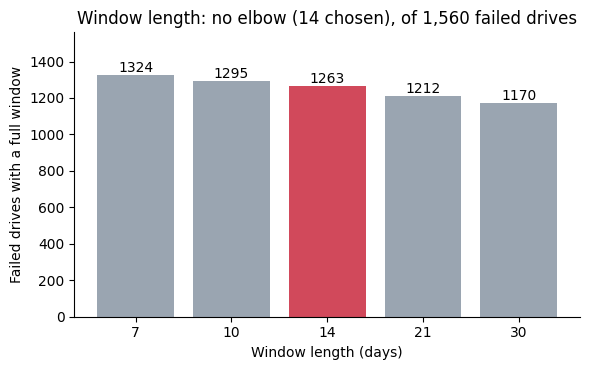

In [11]:
n = {w: int(full_window(w).sum()) for w in (7, 10, 14, 21, 30)}
fig, ax = plt.subplots(figsize=(6, 3.8))
bars = ax.bar([str(k) for k in n], list(n.values()),
              color=["#d1495b" if k == WINDOW_DAYS else "#9aa5b1" for k in n])
ax.bar_label(bars); ax.set_ylim(0, len(failed_ids))
ax.set_xlabel("Window length (days)"); ax.set_ylabel("Failed drives with a full window")
ax.set_title(f"Window length: no elbow ({WINDOW_DAYS} chosen), of {len(failed_ids):,} failed drives")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
del sub; _ = gc.collect()

### Why some failed drives are short

**Question.** Why do some failed drives lack a full 14-day window?

**Finding.** 297 of 1,560 failed drives are short at 14 days: 21 because the data starts there (January 2023), 5 because the drive is young, and 271 because days are missing inside the window. Missing days are the main cause.

**Decision.** Keep the rule that a window needs 14 consecutive days, and apply the same rule to healthy windows. The size of the gaps has not been studied; filling small gaps is a possible later test.

In [12]:
WARN = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw"]
failed = df.loc[df["failure"] == 1, "serial_number"]
h = df.loc[df["serial_number"].isin(failed), ["serial_number", "date"] + WARN].copy()
h["days_before"] = (h.groupby("serial_number", observed=True)["date"].transform("max") - h["date"]).dt.days
h["alarm"] = (h[WARN] > 0).any(axis=1)

g = h.groupby("serial_number", observed=True)["alarm"]
ever, chronic = g.any(), g.first()
onset = h.loc[h["alarm"]].groupby("serial_number", observed=True)["days_before"].max()
clean = chronic[~chronic].index.intersection(onset.index)

print("silent failures:", int((~ever).sum()), "of", len(ever))
print("alarming at first sight (old damage):", int(chronic.sum()))
print(onset.loc[clean].describe(percentiles=[.1, .25, .5, .75, .9]))

per_drive = (df.groupby("serial_number", observed=True)[WARN].max() > 0).any(axis=1)
print("healthy drives that ever alarm:", round(per_drive[~per_drive.index.isin(ever.index)].mean(), 3))
del h; gc.collect()

silent failures: 179 of 1560
alarming at first sight (old damage): 356
count    1025.000000
mean      150.025366
std       184.575668
min         0.000000
10%         6.000000
25%        21.000000
50%        72.000000
75%       208.000000
90%       422.000000
max       949.000000
Name: days_before, dtype: float64
healthy drives that ever alarm: 0.166


0

## 3. Warning signs

**Question.** Do failed drives show a nonzero reallocated (5), reported uncorrectable (187), command timeout (188) or pending (197) counter, and how early?

**Finding.** 179 of 1,560 failed drives (11.5%) never trip any of the four counters. 356 were already alarming when first seen (old damage, not a new warning). For the 1,025 drives where the start of the alarm was observed, the median onset is 72 days before failure (25% within 21 days, 10% within 6). Among healthy drives, 16.6% ever trip one of the counters, so the contrast with failed drives is weaker than it first looks.

**Decision.** These counters carry real signal, but some failures give no warning on them, which caps what any model on these attributes can catch. Because healthy drives also alarm, the model should use the change in a counter (Section 8), not only "has it ever been nonzero".

In [13]:
cols = [c for c in df.columns if c.startswith("smart_")]
s = df.sample(500_000, random_state=0)
print(s[cols].describe(percentiles=[.01, .5, .99]).T[["min", "50%", "99%", "max"]].round(1))
del s

                          min           50%           99%           max
smart_1_raw             592.0  1.222151e+08  2.416779e+08  2.441404e+08
smart_4_raw               1.0  1.100000e+01  7.300000e+01  3.869000e+03
smart_5_normalized        6.0  1.000000e+02  1.000000e+02  1.000000e+02
smart_5_raw               0.0  0.000000e+00  1.232000e+03  6.212000e+04
smart_7_raw             664.0  5.026490e+08  9.924034e+08  5.945105e+12
smart_9_raw               0.0  3.683400e+04  5.290840e+04  5.460900e+04
smart_12_raw              0.0  1.000000e+01  5.500000e+01  3.867000e+03
smart_187_normalized      1.0  1.000000e+02  1.000000e+02  1.000000e+02
smart_187_raw             0.0  0.000000e+00  1.400000e+01  6.553500e+04
smart_188_normalized     30.0  1.000000e+02  1.000000e+02  1.000000e+02
smart_188_raw             0.0  0.000000e+00  2.577020e+10  1.262740e+12
smart_190_raw            15.0  3.100000e+01  4.700000e+01  6.200000e+01
smart_192_raw             0.0  3.000000e+00  6.030000e+02  2.761

## 4. Value ranges

**Question.** What do the raw values look like?

**Finding.** Counters 5, 187, 188, 197, 198 and 199 are zero for most rows, with very large maxima; 197 has a 99th percentile of 0 but a maximum of 17,160. Attribute 187 reaches 65,535, which looks like a 16-bit ceiling. Attributes 192 and 193 are nonzero in most rows (cumulative counts). Columns 1, 7 and 188 hold very large values (smart_7 maximum near 6e12), which suggests packed numbers (an inference from the ranges). Normalized columns are almost always 100. Columns 241 and 242 are large cumulative totals.

**Decision.** Use `log1p` on counters 5, 187 and 197, whose nonzero values are very skewed (see the histograms below). Counter 188 is used as a nonzero flag, because the log did not help it. Other columns are left unscaled for now.

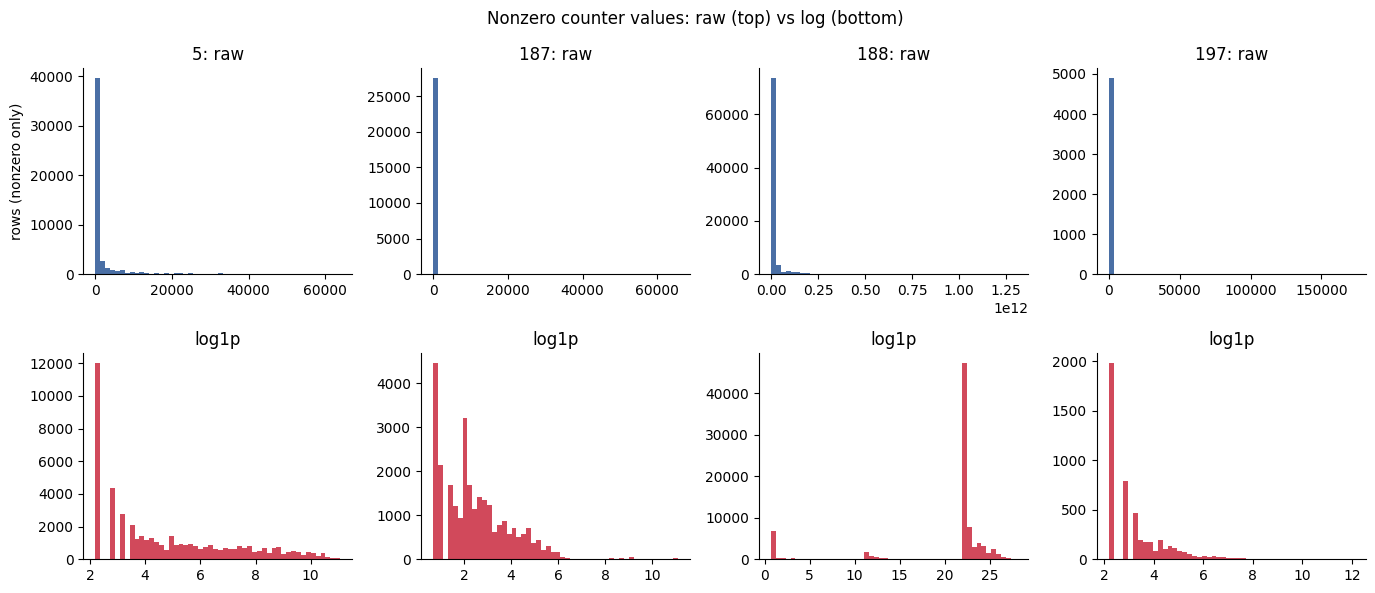

27

In [14]:
CNT = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw"]
s3 = df.sample(1_000_000, random_state=2)
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for j, c in enumerate(CNT):
    v = s3[c].dropna(); v = v[v > 0]
    axes[0, j].hist(v, bins=50, color="#4a6fa5"); axes[0, j].set_title(c.replace("smart_", "").replace("_raw", "") + ": raw")
    axes[1, j].hist(np.log1p(v), bins=50, color="#d1495b"); axes[1, j].set_title("log1p")
    for ax in axes[:, j]: ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].set_ylabel("rows (nonzero only)")
plt.suptitle("Nonzero counter values: raw (top) vs log (bottom)")
plt.tight_layout(); plt.show(); del s3; gc.collect()

In [15]:
pairs = [("smart_197_raw", "smart_198_raw"), ("smart_190_raw", "smart_194_raw"),
         ("smart_1_raw", "smart_195_raw"), ("smart_4_raw", "smart_12_raw")]
s = df.sample(500_000, random_state=0)
for a, b in pairs:
    same = round((s[a] == s[b]).mean() * 100, 2)
    rho = round(s[a].corr(s[b], method="spearman"), 3)
    print(f"{a} vs {b}: identical in {same}% of rows | spearman {rho}")
del s; _ = gc.collect()

smart_197_raw vs smart_198_raw: identical in 99.99% of rows | spearman 1.0
smart_190_raw vs smart_194_raw: identical in 99.99% of rows | spearman 1.0
smart_1_raw vs smart_195_raw: identical in 99.99% of rows | spearman 1.0
smart_4_raw vs smart_12_raw: identical in 78.71% of rows | spearman 0.992


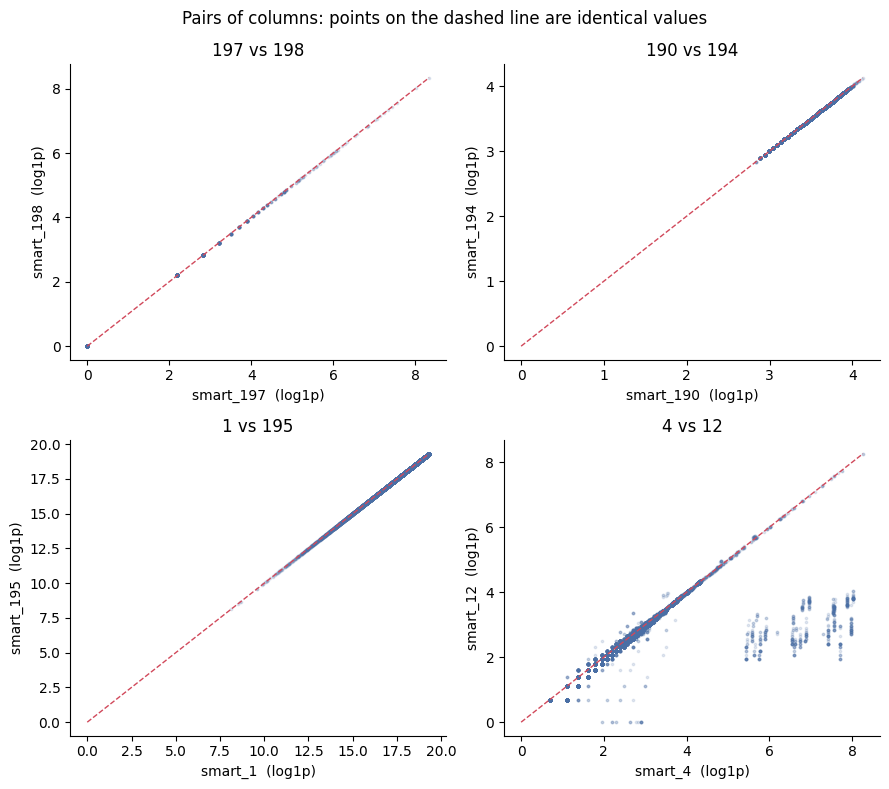

41330

In [16]:
s2 = df.sample(100_000, random_state=1)
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (a, b) in zip(axes.ravel(), pairs):
    x, y = np.log1p(s2[a].clip(lower=0)), np.log1p(s2[b].clip(lower=0))
    ax.scatter(x, y, s=3, alpha=0.15, color="#4a6fa5", rasterized=True)
    lim = [0, max(x.max(), y.max())]
    ax.plot(lim, lim, color="#d1495b", lw=1, ls="--")      # y = x line
    ax.set_xlabel(a.replace("_raw", "") + "  (log1p)"); ax.set_ylabel(b.replace("_raw", "") + "  (log1p)")
    ax.set_title(a.replace("smart_", "").replace("_raw", "") + " vs " + b.replace("smart_", "").replace("_raw", ""))
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Pairs of columns: points on the dashed line are identical values")
plt.tight_layout(); plt.show(); del s2; gc.collect()

## 5. Duplicate columns

**Question.** Do any pairs of attributes carry the same information?

**Finding.** Attributes 197/198, 190/194 and 1/195 are identical in 99.99% of rows (Spearman 1.0), so each pair carries one piece of information. 4 and 12 are not identical (78.71% of rows equal, Spearman 0.992): they are strongly related but not copies.

**Decision.** Keep one column from each identical pair: 197 (drop 198), 190 (drop 194) and 1 (drop 195). Keep both 4 and 12 for now and revisit when the first model is built.

In [17]:
cols = [c for c in df.columns if c.startswith("smart_")]
failed_ids = df.loc[df["failure"] == 1, "serial_number"]

# failed drives: last 14 days only
f = df.loc[df["serial_number"].isin(failed_ids)].copy()
f["days_before"] = (f.groupby("serial_number", observed=True)["date"].transform("max") - f["date"]).dt.days
f = f[f["days_before"] < 14]

# healthy drives: random sample of rows
s = df.sample(600_000, random_state=0)
s = s[~s["serial_number"].isin(failed_ids)]

out = pd.DataFrame({
    "healthy_median": s[cols].median(),
    "failed_median": f[cols].median(),
    "healthy_%nonzero": (s[cols] > 0).mean() * 100,
    "failed_%nonzero": (f[cols] > 0).mean() * 100,
}).round(2)
print(out)
del f, s; gc.collect()

                      healthy_median  failed_median  healthy_%nonzero  \
smart_1_raw             1.222786e+08   1.231169e+08             99.99   
smart_4_raw             1.100000e+01   1.100000e+01             99.99   
smart_5_normalized      1.000000e+02   1.000000e+02             99.99   
smart_5_raw             0.000000e+00   4.000000e+01              4.26   
smart_7_raw             5.022659e+08   5.209468e+08             99.99   
smart_9_raw             3.705000e+04   3.599500e+04             99.99   
smart_12_raw            1.000000e+01   1.100000e+01             99.98   
smart_187_normalized    1.000000e+02   8.700000e+01             99.99   
smart_187_raw           0.000000e+00   1.300000e+01              2.14   
smart_188_normalized    1.000000e+02   1.000000e+02             99.99   
smart_188_raw           0.000000e+00   0.000000e+00              7.94   
smart_190_raw           3.100000e+01   3.200000e+01             99.99   
smart_192_raw           3.000000e+00   3.000000e+00

0

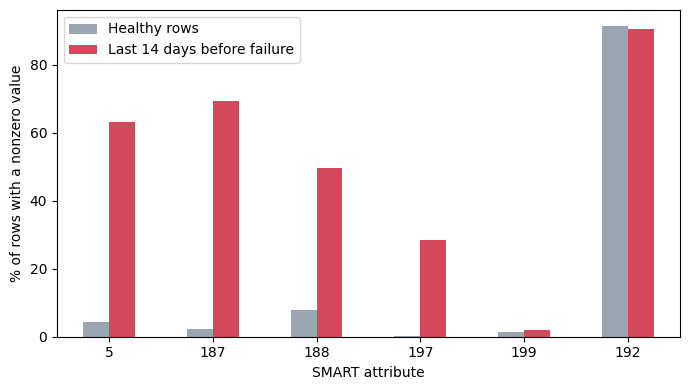

In [18]:
show = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw", "smart_199_raw", "smart_192_raw"]
plot_df = out.loc[show, ["healthy_%nonzero", "failed_%nonzero"]]
plot_df.index = [c.replace("smart_", "").replace("_raw", "") for c in plot_df.index]

ax = plot_df.plot.bar(figsize=(7, 4), color=["#9aa5b1", "#d1495b"])
ax.set_ylabel("% of rows with a nonzero value")
ax.set_xlabel("SMART attribute")
ax.legend(["Healthy rows", "Last 14 days before failure"])
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

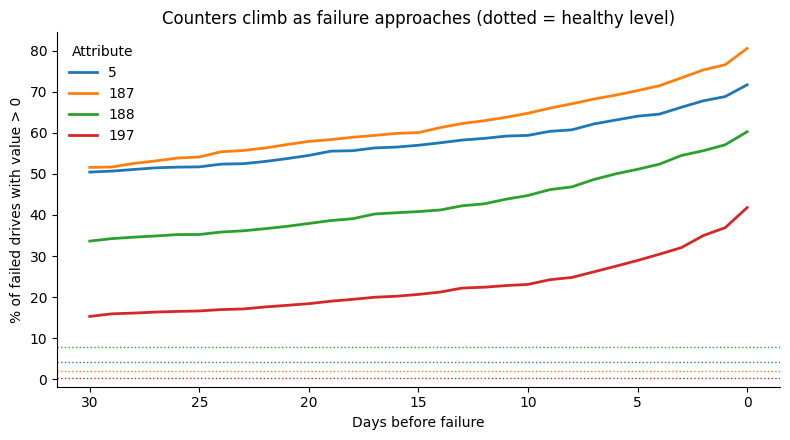

3689

In [19]:
CNT = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw"]
fid = df.loc[df["failure"] == 1, "serial_number"].unique()
t = df.loc[df["serial_number"].isin(fid), ["serial_number", "date"] + CNT]
t = t.assign(days_before=(t.groupby("serial_number", observed=True)["date"].transform("max") - t["date"]).dt.days)
t = t[t["days_before"] <= 30]
share = (t[CNT] > 0).groupby(t["days_before"]).mean() * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
for c, lab in zip(CNT, ["5", "187", "188", "197"]):
    ax.plot(share.index, share[c], label=lab, lw=2)
    ax.axhline(out.loc[c, "healthy_%nonzero"], ls=":", lw=1, color=ax.lines[-1].get_color())
ax.invert_xaxis(); ax.set_xlabel("Days before failure"); ax.set_ylabel("% of failed drives with value > 0")
ax.set_title("Counters climb as failure approaches (dotted = healthy level)")
ax.legend(title="Attribute", frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show(); del t; gc.collect()

## 6. Failing vs healthy: which columns differ

**Question.** Which attributes look different in the last 14 days before a failure than in healthy drives?

**Finding.** Share of nonzero rows, healthy vs last 14 days of failing drives: 197/198 0.35% vs 28.5%; 187 2.1% vs 69.4%; 5 4.3% vs 63.2%; 188 7.9% vs 49.7%. Attributes 199 (1.4% vs 1.9%) and 192 (91.5% vs 90.6%) barely differ. Temperature (190/194) has similar medians (31 healthy vs 32 failing), a weak signal. For attributes that are nonzero in almost every row, this test cannot judge them. The comparison mixes old damage with fresh onset.

**Decision.** Keep 5, 187, 188 and 197 as core inputs. 199 and 192 are weak candidates for removal. Keep `smart_190_raw` as a low-priority input (194 appears identical; see Section 5); no dedicated temperature section, as the effect is small.

In [20]:
cols = [c for c in df.columns if c.startswith("smart_") and "normalized" not in c]
failed_ids = df.loc[df["failure"] == 1, "serial_number"]

f = df.loc[df["serial_number"].isin(failed_ids), ["serial_number", "date"] + cols]
f = f.assign(db=(f.groupby("serial_number", observed=True)["date"].transform("max") - f["date"]).dt.days)
f = f[f["db"] < 14].drop(columns=["date", "db"])

hid = df.loc[~df["serial_number"].isin(failed_ids), "serial_number"].drop_duplicates().sample(10000, random_state=0)
h = df.loc[df["serial_number"].isin(hid), ["serial_number"] + cols].groupby("serial_number", observed=True).tail(14)

res = {}
for name, d in [("failed", f), ("healthy", h)]:
    g = d.groupby("serial_number", observed=True)[cols]
    res[name] = ((g.last() - g.first()) != 0).mean() * 100     # % of drives whose value changed
print(pd.DataFrame(res).round(1).to_string())
del f, h; gc.collect()

               failed  healthy
smart_1_raw      99.4    100.0
smart_4_raw      25.9      2.5
smart_5_raw      57.8      1.1
smart_7_raw      99.4    100.0
smart_9_raw      99.4    100.0
smart_12_raw     12.7      2.4
smart_187_raw    74.0      0.9
smart_188_raw    47.2      0.5
smart_190_raw    67.9     51.0
smart_192_raw    24.8     17.7
smart_193_raw    99.2    100.0
smart_194_raw    67.9     51.0
smart_195_raw    99.4    100.0
smart_197_raw    36.0      0.4
smart_198_raw    36.0      0.4
smart_199_raw     0.4      0.2
smart_240_raw    99.4    100.0
smart_241_raw    99.2    100.0
smart_242_raw    99.4    100.0


0

## 7. Columns that change before failure

**Question.** For attributes where "nonzero" says nothing, do they change more often before failure?

**Finding.** Share of drives whose value changed inside the 14-day window, failed vs 10,000 healthy drives: 4: 25.9% vs 2.5%; 12: 12.7% vs 2.4%; 190/194: 67.9% vs 51.0%; 192: 24.8% vs 17.7%; 199: 0.4% vs 0.2%. Attributes 1, 7, 9, 193, 195 and 240 to 242 change on nearly every drive, so this test cannot judge them.

**Decision.** Add 4 and 12 as candidate inputs (subject to the duplicate check in Section 5). Temperature and 192 are weak candidates. 199 is a drop candidate.

In [21]:
CNT = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw"]
failed_ids = df.loc[df["failure"] == 1, "serial_number"]

f = df.loc[df["serial_number"].isin(failed_ids), ["serial_number", "date"] + CNT]
f = f.assign(db=(f.groupby("serial_number", observed=True)["date"].transform("max") - f["date"]).dt.days)
f = f[f["db"] < 14]

hid = df.loc[~df["serial_number"].isin(failed_ids), "serial_number"].drop_duplicates().sample(10000, random_state=0)
h = df.loc[df["serial_number"].isin(hid), ["serial_number"] + CNT]
h = h.groupby("serial_number", observed=True).tail(14)     # each drive's last 14 rows

lvl, rise = {}, {}
for name, d in [("failed", f), ("healthy", h)]:
    g = d.groupby("serial_number", observed=True)[CNT]
    end, change = g.last(), g.last() - g.first()
    lvl[name] = (end > 0).mean() * 100
    rise[name] = (change > 0).mean() * 100
print("Level > 0 at end (%)"); print(pd.DataFrame(lvl).round(1).to_string())
print("Rose inside window (%)"); print(pd.DataFrame(rise).round(1).to_string())
del f, h; _ = gc.collect()

Level > 0 at end (%)
               failed  healthy
smart_5_raw      72.0      7.1
smart_187_raw    80.7      4.3
smart_188_raw    60.6      9.5
smart_197_raw    41.9      1.0
Rose inside window (%)
               failed  healthy
smart_5_raw      56.7      1.0
smart_187_raw    74.0      0.9
smart_188_raw    47.2      0.5
smart_197_raw    34.1      0.3


## 8. Level or change

**Question.** Is it better to give the model the counter's level, or how much it changed inside the window?

**Finding.** Failed drives (last 14 days before failure) vs 10,000 healthy drives (last 14 rows). Level > 0 at the end of the window: 5: 72.0% vs 7.1%; 187: 80.7% vs 4.3%; 188: 60.6% vs 9.5%; 197: 41.9% vs 1.0%. Rose inside the window: 5: 56.7% vs 1.0%; 187: 74.0% vs 0.9%; 188: 47.2% vs 0.5%; 197: 34.1% vs 0.3%.” Delete the sentence about “only a few drives

**Decision.** Give the model both level and change (the daily difference) for 5, 187, 188 and 197. Change separates the classes much better than level alone.

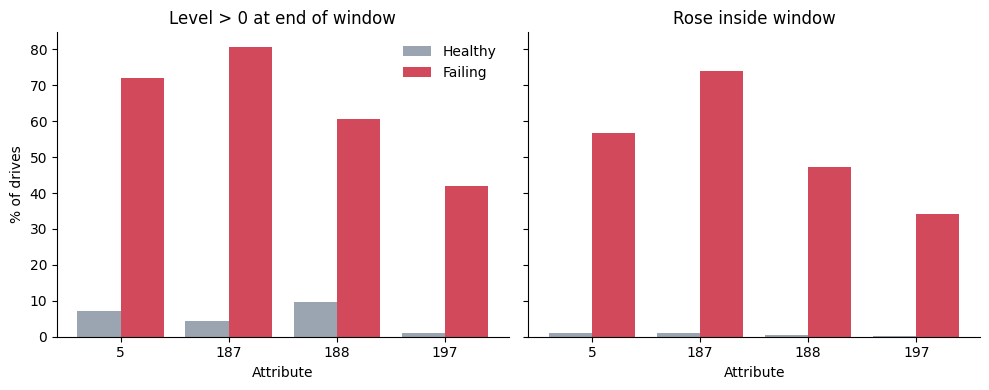

In [22]:
names = [c.replace("smart_", "").replace("_raw", "") for c in CNT]
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, d, ttl in [(axes[0], lvl, "Level > 0 at end of window"), (axes[1], rise, "Rose inside window")]:
    x = np.arange(len(CNT))
    ax.bar(x - .2, d["healthy"], .4, label="Healthy", color="#9aa5b1")
    ax.bar(x + .2, d["failed"], .4, label="Failing", color="#d1495b")
    ax.set_xticks(x); ax.set_xticklabels(names); ax.set_title(ttl); ax.set_xlabel("Attribute")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("% of drives"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

             failures  drive_days  drive_years  per_100_drive_years
smart_9_raw                                                        
[0, 1)             27      130784       358.31                 7.54
[1, 2)             12      181332       496.80                 2.42
[2, 3)            112     2041198      5592.32                 2.00
[3, 4)            538     6755145     18507.25                 2.91
[4, 5)            469     6818994     18682.18                 2.51
[5, 6)            374     4832294     13239.16                 2.82
[6, 8)             14      298453       817.68                 1.71
failures with a usable age: 1546 of 1560


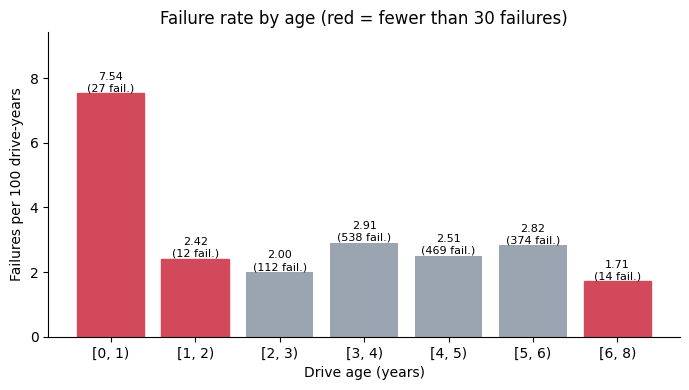

In [23]:
age_y = df["smart_9_raw"] / 8760                      # power-on hours -> years
band = pd.cut(age_y, [0, 1, 2, 3, 4, 5, 6, 8], right=False)
g = df.groupby(band, observed=True)["failure"].agg(failures="sum", drive_days="size")
g["drive_years"] = g["drive_days"] / 365
g["per_100_drive_years"] = g["failures"] / g["drive_years"] * 100
print(g.round(2).to_string())
print("failures with a usable age:", int(g["failures"].sum()), "of", int(df["failure"].sum()))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(g.index.astype(str), g["per_100_drive_years"], color="#9aa5b1")
for i, f in enumerate(g["failures"]):
    if f < 30:
        bars[i].set_color("#d1495b")                   # red = few failures behind the bar
ax.bar_label(bars, labels=[f"{r:.2f}\n({int(f)} fail.)" for r, f in zip(g["per_100_drive_years"], g["failures"])], fontsize=8)
ax.set_xlabel("Drive age (years)"); ax.set_ylabel("Failures per 100 drive-years")
ax.set_ylim(0, g["per_100_drive_years"].max() * 1.25)
ax.set_title("Failure rate by age (red = fewer than 30 failures)")
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
del age_y, band; _ = gc.collect()

## 9. Power-on hours (drive age)

**Question.** Does the failure rate change with a drive's age?

**Finding.** Failures per 100 drive-years by age band: 0-1 years 7.54 (27 failures, 358 drive-years); 1-2: 2.42; 2-3: 2.00; 3-4: 2.91; 4-5: 2.51; 5-6: 2.82; 6-8: 1.71 (14 failures). From year 1 onward the rate stays between about 2 and 3 with no trend; the 0-1 and 6-8 bands rest on few failures. 14 of the 1,560 failures have no usable age (missing power-on hours) and are not in the bands. A first attempt grouping drives by age at their last row was discarded, because failed and healthy drives were measured at different dates.

**Decision.** Exclude `smart_9_raw` and its near-copy `smart_240_raw`. No clear age effect after year 1, Paper B dropped it for the same reason, and the end user may not know the drive's age.

# Decisions carried into the model stage


- **Cleaning.** Each drive is cut at its first failure.
- **Window.** 14 consecutive days (`WINDOW_DAYS = 14`); compare 7 and 21 later. A window must have no missing day, for failed and healthy windows alike.
- **Core inputs.** SMART 5, 187, 188 and 197, each as level and as change within the window.
- **Candidates.** 4 and 12 (both kept), temperature 190 (194 is a copy); 199 and 192 are weak, 199 is a drop candidate.
- **Dropped.** Copies 198, 194 and 195; age columns `smart_9_raw` and `smart_240_raw`; columns that are empty or constant for this model.
- **Transform.** `log1p` on counters 5, 187 and 197; 188 as a nonzero flag.
- **Splits.** By date, never random. The 2026 quarters are held out for validation and test and have not been explored.
- **Known limits.** 179 failed drives (11.5%) show no warning on the four counters; 16.6% of healthy drives also alarm at some point; 297 failed drives lack a full 14-day window (271 because of missing days).

# Modelling, deleted section please ignore.

**Goal.** Predict hard drive failure from daily SMART readings, with a baseline model first and a 1D CNN to compare.

## 1. Setup and decisions

Decisions carried over from the EDA (`01_data_loading_and_eda`):
- **Window length:** 14 consecutive days (`WINDOW_DAYS = 14`); compare 7 and 21 later.
- **Core inputs:** SMART 5, 187, 188, 197, each as level and as change within the window.
- **Extra candidates:** 4, 12 and 190.
- **Dropped:** copies 198, 194, 195; age columns 9 and 240.
- **Transforms:** `log1p` on 5, 187 and 197. Counter 188 is used as "nonzero" for now.
- **Missing values:** a window with any missing day or empty reading is dropped, for failed and healthy windows alike.

Decisions to settle in this notebook:
1. **Horizon.** Where the window ends relative to failure. Horizon 0 means the window ends on the failure day (detecting a drive that is already failing). Horizon N means it ends N days earlier (predicting failure N days ahead). Starting value: 7.
2. **Healthy windows.** There are about 1,260 failed windows and millions of possible healthy ones. We sample healthy windows from different drives.
3. **Split.** By drive, never by row, so no drive appears in two sets. Later held-out quarters are for validation and test.
4. **Metrics.** Precision-recall AUC, and recall at a fixed false-alarm rate. Not accuracy, because failures are rare.
5. **Scaling.** Fitted on the training set only.

In [24]:

WINDOW_DAYS = 14
HORIZON = 7          # window ends this many days before the failure day (0 = ends on failure day)
CORE = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw"]
EXTRA = ["smart_4_raw", "smart_12_raw", "smart_190_raw"]
FEATURES = CORE + EXTRA

df = pd.read_parquet("clean_train.parquet", columns=["serial_number", "date", "failure"] + FEATURES)
df["serial_number"] = df["serial_number"].astype("category")
print(df.shape, "| drives:", df["serial_number"].nunique(), "| failed:", int(df["failure"].sum()))
print(df.dtypes.to_string())
print("memory (GB):", round(df.memory_usage(deep=True).sum() / 1e9, 2))

(21059498, 10) | drives: 20236 | failed: 1560
serial_number          category
date             datetime64[us]
failure                   int64
smart_5_raw             float32
smart_187_raw           float32
smart_188_raw           float32
smart_197_raw           float32
smart_4_raw             float32
smart_12_raw            float32
smart_190_raw           float32
memory (GB): 0.97


## 2. Building the windows

**Question.** How many usable 14-day windows do we get from failed and from healthy drives, with the horizon set above?

**Method.**
- A failed drive has one positive window: the 14 days ending `HORIZON` days before its failure day.
- Healthy drives (never failed in the training period) give negative windows, taken at random end days from the whole period.
- A window is usable only if it has 14 consecutive days and no empty reading (the EDA decision).
- Each window keeps its drive and end date, so the split can be done by drive and by time later.

**Caveat.** A drive that looks healthy here might fail in the held-out period. This is a small source of label noise in the negatives, and it cannot be removed without looking at later data.



**Finding.** With a horizon of 7 and a 14-day window, 1,209 of the 1,560 failed drives give a usable window (351 are lost; at horizon 0 only 297 were short, because ending 7 days earlier needs a longer history). From healthy drives we kept 48,582 windows from 17,240 drives. The data are 49,791 windows of 14 days × 7 columns, and 2.43% are positive. This share is set by our sampling and is far higher than the real failure rate. The end dates of failed and healthy windows cover the same period (Jan 2023 to Dec 2025), so there is no time shift between the classes.

**Decision.** Keep these windows. The lost failed drives are those with too little history or missing days, so the model never sees that kind of failure. Evaluate on a realistic share of failures later, not the 2.43%.

In [25]:
# 1. make sure each drive's rows are contiguous and in date order (the windows rely on this)
codes = df["serial_number"].cat.codes.to_numpy()
dates = df["date"].to_numpy()
n = len(df)
starts = np.r_[0, np.flatnonzero(np.diff(codes) != 0) + 1]
print("drive blocks:", len(starts), "| drives:", df["serial_number"].nunique())
same = codes[1:] == codes[:-1]
print("dates strictly increasing within each drive:", bool((np.diff(dates)[same] > np.timedelta64(0)).all()))
pos = np.arange(n) - np.repeat(starts, np.diff(np.r_[starts, n]))     # row number within its drive

# 2. which rows can end a complete window?
X = df[FEATURES].to_numpy(np.float32)
bad = np.isnan(X).any(axis=1)
cum = np.r_[0, np.cumsum(bad)]
W = WINDOW_DAYS

def ends_complete_window(e):
    ok = pos[e] >= W - 1
    s = np.where(ok, e - (W - 1), 0)
    span = (dates[e] - dates[s]).astype("timedelta64[D]").astype(int)
    return ok & (span == W - 1) & ((cum[e + 1] - cum[s]) == 0)

# 3. failed drives: window ends HORIZON days before the failure row
fr = np.flatnonzero(df["failure"].to_numpy() == 1)
has_rows = pos[fr] >= HORIZON
e_f = np.where(has_rows, fr - HORIZON, 0)
exact_gap = (dates[fr] - dates[e_f]).astype("timedelta64[D]").astype(int) == HORIZON
ok_f = has_rows & exact_gap & ends_complete_window(e_f)
print(f"\nfailed drives: {len(fr)} | usable windows: {int(ok_f.sum())} | lost: {int((~ok_f).sum())}")
e_f = e_f[ok_f]

# 4. healthy drives: random end rows from drives that never failed
rng = np.random.default_rng(0)
healthy_row = ~np.isin(codes, codes[fr])
cand = np.flatnonzero(healthy_row & (pos >= W - 1))
e_h = rng.choice(cand, size=min(50_000, len(cand)), replace=False)
e_h = e_h[ends_complete_window(e_h)]
print(f"healthy windows kept: {len(e_h)} from {len(np.unique(codes[e_h]))} drives")

# 5. build the arrays: (windows, days, features), oldest day first
offs = np.arange(-(W - 1), 1)
X_win = np.concatenate([X[e_f[:, None] + offs], X[e_h[:, None] + offs]])
y = np.r_[np.ones(len(e_f), dtype=np.int8), np.zeros(len(e_h), dtype=np.int8)]
ends = np.r_[e_f, e_h]
meta = pd.DataFrame({"drive": codes[ends], "end_date": dates[ends], "y": y})
print("\nX_win shape:", X_win.shape, "| positives:", int(y.sum()), "| negatives:", int((1 - y).sum()))
print("positive share:", round(y.mean() * 100, 2), "%")
print("end dates, failed vs healthy:")
print(meta.groupby("y")["end_date"].describe()[["min", "50%", "max"]])
del bad, cum; _ = gc.collect()

drive blocks: 20236 | drives: 20236
dates strictly increasing within each drive: True

failed drives: 1560 | usable windows: 1209 | lost: 351
healthy windows kept: 48582 from 17240 drives

X_win shape: (49791, 14, 7) | positives: 1209 | negatives: 48582
positive share: 2.43 %
end dates, failed vs healthy:
                   min                  50%                  max
y                                                               
0  2023-01-14 00:00:00  2024-07-18 00:00:00  2025-12-31 00:00:00
1  2023-01-14 00:00:00  2024-04-27 00:00:00  2025-12-21 00:00:00


## 3. Splitting by drive

**Question.** How do we separate training from development data without leaking information?

**Method.** Windows from the same drive look alike, so all windows of a drive stay in one set. Failed drives and healthy drives are split separately (80% train, 20% dev), so the dev set keeps failures. The later held-out quarters stay untouched for the final validation and test.

**Finding.** Train has 39,763 windows (968 positive, 14,760 drives) and dev has 10,028 windows (241 positive, 3,689 drives). The positive share is 2.43% vs 2.40%, and no drive is in both sets.

**Decision.** Use this split for developing and comparing the baseline and the CNN. The dev set has only 241 positives, so its scores are noisy and small differences between models mean little. The final numbers come from the held-out later quarters.

In [26]:
rng = np.random.default_rng(42)
fail_drives = meta.loc[meta["y"] == 1, "drive"].unique()
heal_drives = meta.loc[meta["y"] == 0, "drive"].unique()

def pick(ids, frac):
    ids = rng.permutation(ids)
    return set(ids[: int(len(ids) * frac)])

dev_drives = pick(fail_drives, 0.2) | pick(heal_drives, 0.2)
meta["split"] = np.where(meta["drive"].isin(dev_drives), "dev", "train")

summary = meta.groupby("split").agg(windows=("y", "size"), positives=("y", "sum"), drives=("drive", "nunique"))
summary["positive_%"] = (summary["positives"] / summary["windows"] * 100).round(2)
print(summary)
tr = set(meta.loc[meta["split"] == "train", "drive"]); dv = set(meta.loc[meta["split"] == "dev", "drive"])
print("drives in both sets:", len(tr & dv))

       windows  positives  drives  positive_%
split                                        
dev      10028        241    3689        2.40
train    39763        968   14760        2.43
drives in both sets: 0


## 4. Baseline features

**Question.** What summary of each 14-day window should the baseline model see?

**Method.** The baseline gets a few numbers per window instead of the whole sequence, taken from the EDA:
- For counters 5, 187 and 197: the end value and the change across the window, both on a `log1p` scale, plus "nonzero at the end" and "rose inside the window" flags.
- For counter 188: only the two flags (the log did not help, see Section 4 of the EDA).
- For 4 and 12: end value (log) and whether it changed.
- For 190 (temperature): the end value and the change.

The CNN will see the raw 14-day sequences instead, so any extra signal there can be compared fairly.

**Finding.** 20 features, no missing values. Counters 5, 187 and 197 separate failing from healthy windows strongly, both in the end value (5: 3.58 vs 0.20 on the log scale) and in rising inside the window (187: 51% vs 0.1%). Counter 188 separates less (nonzero at the end 48% vs 8%). Columns 4, 12 and temperature (190) differ only slightly (4 and 12 end values 2.49 vs 2.48; temperature 32.4 vs 31.6).

**Decision.** Keep all 20 features for the first baseline, so we can see what the weak columns add. The counter features should carry most of the signal.

In [27]:
names = [c.replace("smart_", "").replace("_raw", "") for c in FEATURES]
J = {n: i for i, n in enumerate(names)}

def make_features(Xw):
    first, last = Xw[:, 0, :], Xw[:, -1, :]
    f = {}
    for n in ["5", "187", "197"]:
        a, b = np.log1p(np.clip(first[:, J[n]], 0, None)), np.log1p(np.clip(last[:, J[n]], 0, None))
        f[f"{n}_end_log"], f[f"{n}_change_log"] = b, b - a
        f[f"{n}_end_nz"], f[f"{n}_rose"] = (last[:, J[n]] > 0), (last[:, J[n]] > first[:, J[n]])
    f["188_end_nz"], f["188_rose"] = (last[:, J["188"]] > 0), (last[:, J["188"]] > first[:, J["188"]])
    for n in ["4", "12"]:
        f[f"{n}_end_log"] = np.log1p(np.clip(last[:, J[n]], 0, None))
        f[f"{n}_changed"] = last[:, J[n]] != first[:, J[n]]
    f["190_end"], f["190_change"] = last[:, J["190"]], last[:, J["190"]] - first[:, J["190"]]
    return pd.DataFrame(f).astype("float32")

F = make_features(X_win)
tr_m, dv_m = (meta["split"] == "train").to_numpy(), (meta["split"] == "dev").to_numpy()
print("features:", F.shape[1], "| NaNs:", int(F.isna().sum().sum()))
print(F.groupby(y).mean().T.round(3).rename(columns={0: "healthy", 1: "failing"}).to_string())

features: 20 | NaNs: 0
                healthy    failing
5_end_log         0.203   3.576000
5_change_log      0.003   0.595000
5_end_nz          0.044   0.596000
5_rose            0.003   0.392000
187_end_log       0.050   2.229000
187_change_log    0.001   0.522000
187_end_nz        0.022   0.658000
187_rose          0.001   0.505000
197_end_log       0.010   1.026000
197_change_log    0.000   0.370000
197_end_nz        0.003   0.247000
197_rose          0.000   0.172000
188_end_nz        0.080   0.475000
188_rose          0.002   0.285000
4_end_log         2.476   2.492000
4_changed         0.059   0.113000
12_end_log        2.433   2.459000
12_changed        0.059   0.106000
190_end          31.586  32.398998
190_change        0.040   0.083000


## 5. Baseline models

**Question.** How well can simple models predict failure 7 days ahead from these features?

**Method.** Three baselines, all fitted on the train set and scored on the dev set:
- a rule: the number of counters (5, 187, 188, 197) that are nonzero at the end of the window, as a score;
- logistic regression on the scaled features (scaler fitted on train only);
- gradient boosting (shallow trees).

Failures are weighted up in training because they are rare. Metrics: average precision (the area under the precision-recall curve; a random model scores about the failure share, 0.024), and the share of failures caught when only 1% of healthy windows raise an alarm. The dev share of failures is inflated by our sampling, so precision here is better than it would be on real fleet data.

**Finding.** On the dev set (241 failures, random average precision 0.024): the rule "number of counters nonzero" gets average precision 0.499 and catches 48.5% of failures at 1% false alarms. Logistic regression gets 0.705 and 72.6%. Gradient boosting gets 0.684 and 71.8%. The two models are within noise of each other.

**Decision.** Use logistic regression as the reference for the CNN, because it is simple and matches gradient boosting. Compare all models at 1%, 0.3% and 0.1% false alarms and by average precision on the same dev set. Confirm the final choice on the held-out quarters.

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

def recall_at_fpr(yt, s, target=0.01):
    fpr, tpr, _ = roc_curve(yt, s)
    return float(tpr[fpr <= target].max())

Xtr, Xdv, ytr, ydv = F[tr_m], F[dv_m], y[tr_m], y[dv_m]
w = np.where(ytr == 1, (ytr == 0).sum() / (ytr == 1).sum(), 1.0)
sc = StandardScaler().fit(Xtr)

scores = {}
scores["rule: counters nonzero"] = Xdv[["5_end_nz", "187_end_nz", "188_end_nz", "197_end_nz"]].sum(axis=1).to_numpy()
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(sc.transform(Xtr), ytr)
scores["logistic"] = lr.predict_proba(sc.transform(Xdv))[:, 1]
gb = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.1, max_iter=200, random_state=0).fit(Xtr, ytr, sample_weight=w)
scores["grad_boost"] = gb.predict_proba(Xdv)[:, 1]

rows = [{"model": k, "avg_precision": average_precision_score(ydv, s), "roc_auc": roc_auc_score(ydv, s),
         "recall@1%FPR": recall_at_fpr(ydv, s)} for k, s in scores.items()]
print("dev failure share (random model's avg precision):", round(ydv.mean(), 3))
print(pd.DataFrame(rows).round(3).to_string(index=False))

dev failure share (random model's avg precision): 0.024
                 model  avg_precision  roc_auc  recall@1%FPR
rule: counters nonzero          0.499    0.878         0.485
              logistic          0.705    0.891         0.726
            grad_boost          0.684    0.894         0.718


In [29]:
for k, s in scores.items():
    print(k, {f"recall@{t:.2%}FPR": round(recall_at_fpr(ydv, s, t), 3) for t in (0.01, 0.003, 0.001)})

rule: counters nonzero {'recall@1.00%FPR': 0.485, 'recall@0.30%FPR': 0.154, 'recall@0.10%FPR': 0.154}
logistic {'recall@1.00%FPR': 0.726, 'recall@0.30%FPR': 0.61, 'recall@0.10%FPR': 0.481}
grad_boost {'recall@1.00%FPR': 0.718, 'recall@0.30%FPR': 0.618, 'recall@0.10%FPR': 0.469}


At stricter false-alarm levels (recall at 0.3% / 0.1% false alarms): rule 15% / 15%; logistic 61% / 48%; gradient boosting 62% / 47%. The rule cannot reach these levels because it only takes five values. Using the real failure share (about 1 in 13,500 windows), 48% recall at 0.1% false alarms would mean about 1 real alarm in 30. At 0.1% the dev set has only about 10 false alarms, so these numbers are noisy.